### Policy gradient methods: Minimal example

In this notebook, we illustrate the core concepts of policy gradient methods using 
a simple example.

Image that you're throwing darts at a dart board--blindfolded. After each darts you throw, you are given a reward that depends on how close to the bullseye you are. Based on this information, you explore the space to learn where the target is. Each throw lands at a location that is a normal random variable with a given mean (your intended target) and variance (how accurate you are).

This corresponds to a policy $\pi_\theta(a \;|\; s)$ that is distributed as a Gaussian 
random variable $a \sim N(\mu(s), \sigma^2(s))$. The mean $\mu(s)$ and the standard deviation $\sigma(s)$ will be the outputs of a neural network, much like for a variational autoencoder. The parameters $\theta$ are the weights in the neural network. To compute the gradient of the expected reward, we use automatic differentiation, building up the objective function using PyTorch operations.

The neural network that implements the policy is called the "actor network" since it 
is responsible for deciding which actions are taken. In this particular example, the state is simply a fixed constant.

Our example is adapted (from TensorFlow to PyTorch) from [this blog](https://towardsdatascience.com/a-minimal-working-example-for-continuous-policy-gradients-in-tensorflow-2-0-d3413ec38c6b).


In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [2]:
"""Construct the actor network with mu and sigma as output"""
class ActorNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(1, 5)
        self.hidden2 = nn.Linear(5, 5)
        self.mu = nn.Linear(5, 1)
        self.sigma = nn.Linear(5, 1)

        # Match the Keras Dense defaults (Glorot uniform weights, zero biases)
        for layer in [self.hidden1, self.hidden2, self.mu, self.sigma]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, inputs):
        h = torch.relu(self.hidden1(inputs))
        h = torch.relu(self.hidden2(h))
        mu = self.mu(h)
        sigma = torch.sigmoid(self.sigma(h))
        return mu, sigma

def construct_actor_network():
    actor_network = ActorNetwork()
    return actor_network

In [3]:
"""Weighted Gaussian log likelihood loss function"""
def gaussian_loss(state, action, reward): 
    # Obtain mu and sigma from actor network
    nn_mu, nn_sigma = actor_network(state)
        
    # pdf of Gaussian distribution
    pdf_value = torch.exp(-0.5 *((action - nn_mu) / (nn_sigma))**2) *\
         1/(nn_sigma*np.sqrt(2 *np.pi))

    # Compute log probability
    log_probability = torch.log(pdf_value + 1e-5)
        
    # Compute weighted loss (a scalar, so we can call backward() on it)
    loss_actor = - reward * log_probability
    return loss_actor.sum()

In [4]:
"""Plot output"""
def plot():
    fig = plt.figure(figsize=(10,6))
    ax = fig.add_subplot(1, 1, 1)

    epoch_ar.append(int(i))
    mu_ar.append(float(mu))
    sigma_ar.append(float(sigma))
    reward_ar.append(float(reward))
    target_ar.append(float(mu_target))
    
    ax.plot(epoch_ar,mu_ar,label='mu')
    ax.plot(epoch_ar,sigma_ar,label='sigma')
    ax.plot(epoch_ar,reward_ar,label='reward')
    ax.plot(epoch_ar,target_ar,label='target')

    plt.xlabel('Episode')
    plt.ylabel('Parameter value')
    plt.xlim((0, (int(i/1000)+1)*1000))
    plt.grid()
    plt.legend(loc='best')
    plt.show() 

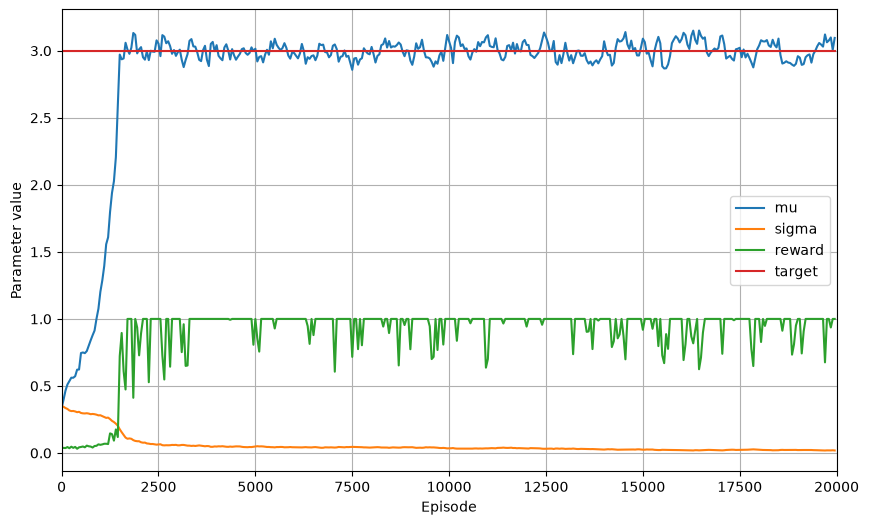

In [5]:
# Initialize fixed state
state = torch.tensor([[1.0]])

# Define properties reward function
mu_target = 3.0
target_precision = 0.10
max_reward = 1.0

# Create actor network
actor_network = construct_actor_network()
opt = torch.optim.Adam(actor_network.parameters(), lr=0.0005)

# Initialize arrays for plot
epoch_ar = []
mu_ar = []
sigma_ar=[]
reward_ar=[]
target_ar=[]

for i in range(20000):    
    
    # Obtain mu and sigma from network (no gradients needed for sampling)
    with torch.no_grad():
        mu, sigma = actor_network(state)
    
    # Draw action from normal distribution
    action = torch.normal(mean=mu, std=sigma)
   
    # Compute reward
    reward = max_reward/ max(target_precision, abs(mu_target-action.item())) * target_precision

    # Update network weights
    opt.zero_grad()

    # Compute Gaussian loss
    loss_value = gaussian_loss(state, action, reward)

    # Compute gradients
    loss_value.backward()

    # Apply gradients to update network weights
    opt.step()
        
    # Update console output and plot
    if np.mod(i, 50) == 0:
        clear_output(wait=True)
        plot() 